# 01 · 从误差反馈到 PID：越接近目标，越要考虑怎么停

本篇先在不限制推力、能看到真实速度的理想条件下解释 P 和 PD，再加入恒定外力、积分和输入饱和。你会看到经典控制的价值，也会看到只对输出误差做文章时需要补上的设计环节。

**学习成果：** 从运动方程得到传递函数；用极点与频率响应解释反馈；实现带抗积分饱和的 PID。


[00 学习地图与小车建模](00_学习地图与小车建模.ipynb) · [01 经典控制与PID](01_经典控制与PID.ipynb) · [02 状态空间与LQR](02_状态空间与LQR.ipynb) · [03 观测器与Kalman滤波](03_观测器与Kalman滤波.ipynb) · [04 从有限时域优化到MPC](04_从有限时域优化到MPC.ipynb) · [05 综合实验与进阶路线](05_综合实验与进阶路线.ipynb)

每篇可独立运行；本篇内按顺序执行。图中英文标签对应正文中文术语，避免依赖本机中文字体。


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal, linalg

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.figsize": (9, 3.8), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.2})
DT = 0.1
MASS, DRAG = 1.0, 0.4
C = np.array([[1.0, 0.0]])

def model(mass=MASS, drag=DRAG):
    Ac = np.array([[0.0, 1.0], [0.0, -drag / mass]])
    Bc = np.array([[0.0], [1.0 / mass]])
    A, B, _, _, _ = signal.cont2discrete((Ac, Bc, C, np.zeros((1, 1))), DT)
    return A, B

A, B = model()
b = B[:, 0]
REF = np.array([1.0, 0.0])

def rollout(policy, steps=120, x0=(0.0, 0.0), disturbance=None, plant=None):
    Ap, Bp = (A, B) if plant is None else plant
    xs, us = [np.array(x0, dtype=float)], []
    for k in range(steps):
        u = float(policy(xs[-1].copy(), k))
        d = 0.0 if disturbance is None else float(disturbance(k))
        xs.append(Ap @ xs[-1] + Bp[:, 0] * (u + d))
        us.append(u)
    return np.asarray(xs), np.asarray(us)

def plot_runs(runs, title, wall=None):
    fig, axes = plt.subplots(3, 1, figsize=(9, 7), sharex=True)
    for label, (xs, us) in runs.items():
        axes[0].plot(np.arange(len(xs))*DT, xs[:, 0], label=label)
        axes[1].plot(np.arange(len(xs))*DT, xs[:, 1], label=label)
        axes[2].step(np.arange(len(us))*DT, us, where="post", label=label)
    axes[0].axhline(REF[0], color="black", ls=":", label="target")
    if wall is not None:
        axes[0].axhline(wall, color="firebrick", ls="--", label="position limit")
    for ax, label in zip(axes, ["position [m]", "velocity [m/s]", "force [N]"]):
        ax.set_ylabel(label)
    axes[0].legend(ncol=3, fontsize=8)
    axes[-1].set_xlabel("time [s]")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


## 1. 传递函数：把内部变量消去，看输入到输出

零初始条件、无外力时，对 $m\ddot p+b_c\dot p=u$ 作 Laplace 变换：

$$G(s)=\frac{P(s)}{U(s)}=\frac{1}{ms^2+b_cs}=\frac{1}{s(s+0.4)}.$$

$s$ 是复频率变量。传递函数描述线性时不变系统的输入输出关系，初始状态另行处理。它与状态空间描述的是同一辆车。

比例控制 $u=K_p(r-p)$ 给出闭环：

$$\frac{P(s)}{R(s)}=\frac{K_p}{ms^2+b_cs+K_p}.$$

与标准二阶式 $s^2+2\zeta\omega_n s+\omega_n^2$ 对照：

$$\omega_n=\sqrt{K_p/m},\qquad \zeta=\frac{b_c}{2\sqrt{mK_p}}.$$

$K_p$ 越大，响应倾向更快，却也减小阻尼比。车快到目标时仍在向前运动，单靠“位置误差变小了”来减力可能刹不住。


Kp=0.5: continuous=[-0.2+0.6782j -0.2-0.6782j], sampled=[0.9792+0.0668j 0.9792-0.0668j], sampled stable=True
Kp=2.0: continuous=[-0.2+1.4j -0.2-1.4j], sampled=[0.9755+0.1379j 0.9755-0.1379j], sampled stable=True
Kp=8.0: continuous=[-0.2+2.8213j -0.2-2.8213j], sampled=[0.9607+0.2773j 0.9607-0.2773j], sampled stable=True


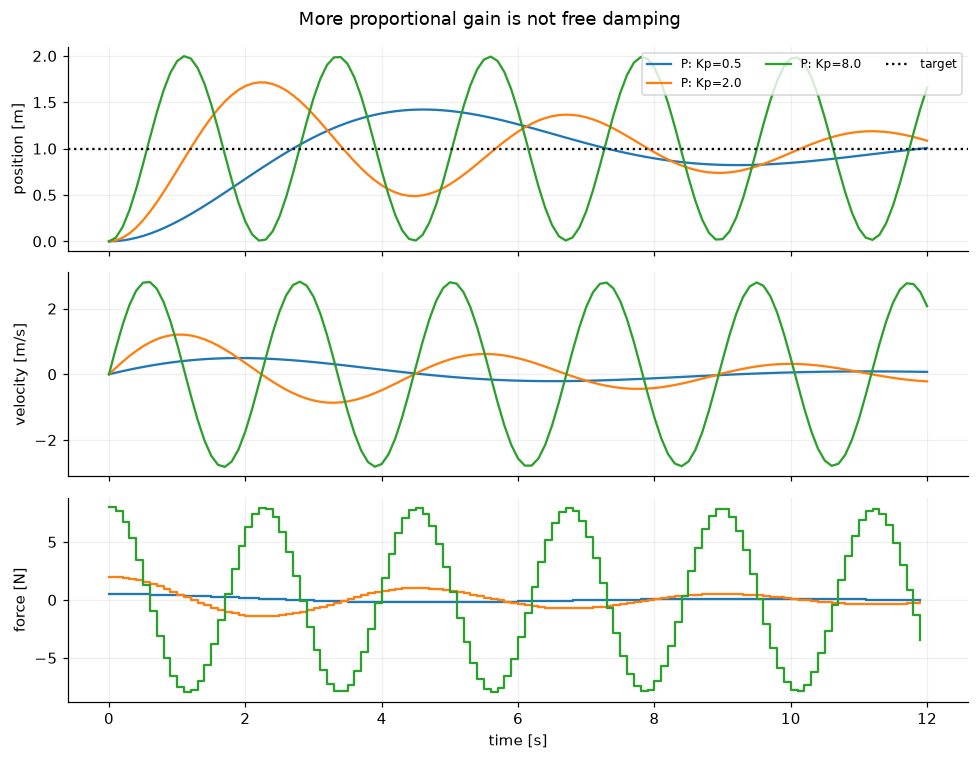

In [2]:
p_runs = {}
for kp in [0.5, 2.0, 8.0]:
    p_runs[f"P: Kp={kp}"] = rollout(lambda x, k, kp=kp: kp*(1-x[0]))
    continuous_poles = np.roots([MASS, DRAG, kp])
    digital_poles = np.linalg.eigvals(A - B @ np.array([[kp, 0.0]]))
    print(f"Kp={kp}: continuous={continuous_poles}, sampled={digital_poles}, "
          f"sampled stable={np.max(np.abs(digital_poles)) < 1}")
plot_runs(p_runs, "More proportional gain is not free damping")


### 连续设计不等于数字实现

上面的公式假定连续反馈，代码每 0.1 秒更新一次。数字闭环矩阵是 $A-B[K_p,0]$，其特征值必须位于单位圆内。大增益时，采样保持会进一步损伤稳定性，所以代码同时报告连续极点与离散极点。

连续稳定要求极点实部小于零；离散稳定要求特征值模小于一。这两个判据都在描述自然响应是否随时间衰减。

## 2. PD：提前识别动量

对于恒定位置目标，用测得速度实现微分项：

$$u=K_p(r-p)-K_dv.$$

闭环特征多项式变为 $ms^2+(b_c+K_d)s+K_p$。$K_d$ 相当于主动增加阻尼。设 $K_p=4,K_d=3.6$，连续模型为 $s^2+4s+4=(s+2)^2$。

我们对**测量值**微分，避免阶跃目标产生 derivative kick。现在使用真实速度是为了隔离控制机制，第 03 篇会去掉这一理想条件。


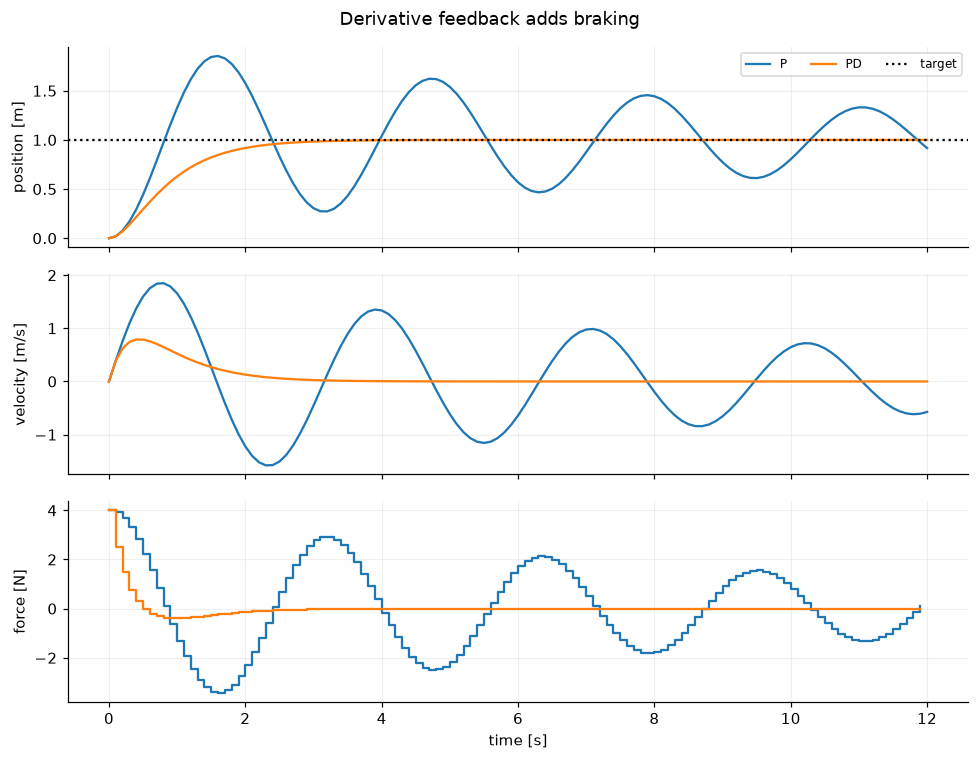

In [3]:
kp, kd = 4.0, 3.6
pd_policy = lambda x, k: kp*(1-x[0]) - kd*x[1]
plot_runs({"P": rollout(lambda x, k: kp*(1-x[0])),
           "PD": rollout(pd_policy)}, "Derivative feedback adds braking")
assert np.max(np.abs(np.linalg.eigvals(A-B@np.array([[kp, kd]])))) < 1


## 3. 频域：反馈不仅要快，还要承受相位滞后

给系统一个正弦输入，稳态输出仍是同频率正弦，幅值与相位改变。把 $s=j\omega$ 代入就得到频率响应。

环路传递函数 $L=CG$，灵敏度 $S=1/(1+L)$，互补灵敏度 $T=L/(1+L)$，且 $S+T=1$。参考到输出是 $T$；测量噪声到输出是 $-T$；输入外力到位置是 $GS$。低频大环路增益有助于减小慢扰动影响，高频仍要避免放大测量噪声。

Bode 图的 0 dB 交越附近，如果相位靠近 $-180^\circ$，负反馈容易因为延迟变得像正反馈。下面画连续模型用于建立直觉，不能把它直接当成数字闭环的精确稳定裕度。

理想微分器高频增益无限增长；工程上常用 $K_ds/(1+\tau_fs)$ 的滤波微分。第三篇改用模型估计速度。


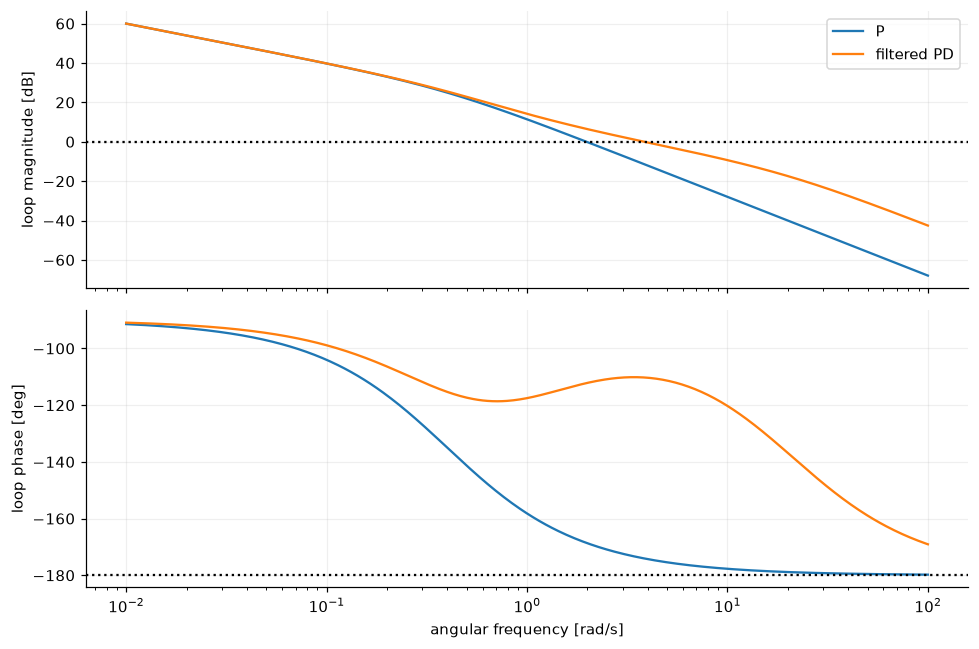

In [4]:
w = np.logspace(-2, 2, 500)
s = 1j*w
G = 1/(MASS*s*s + DRAG*s)
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
for name, controller in {"P": kp+0*s, "filtered PD": kp+kd*s/(1+0.05*s)}.items():
    loop = controller*G
    axes[0].semilogx(w, 20*np.log10(np.abs(loop)), label=name)
    axes[1].semilogx(w, np.rad2deg(np.unwrap(np.angle(loop))))
axes[0].axhline(0, color="black", ls=":")
axes[1].axhline(-180, color="black", ls=":")
axes[0].set_ylabel("loop magnitude [dB]")
axes[1].set_ylabel("loop phase [deg]")
axes[1].set_xlabel("angular frequency [rad/s]")
axes[0].legend()
fig.tight_layout()
plt.show()


## 4. 加入恒定外力：为什么 PD 留下静差？

平衡时 $v=0,\dot v=0$，于是 $0=K_pe+d$，所以 $e_\infty=-d/K_p$。有 $0.2\,\mathrm N$ 的向前外力时，车会停在目标前方约 $0.05\,\mathrm m$，利用负的位置误差产生反向推力。

积分器为控制器提供额外记忆：

$$\dot z=e=r-p,\qquad u=K_pe+K_iz-K_dv.$$

平衡时若积分状态有界，就必须 $e=0$；所需反向推力由 $K_iz$ 提供。这个消除常值扰动误差的思路，也会出现在状态空间积分控制和 offset-free MPC 中。

PID 连续闭环特征多项式：

$$ms^3+(b_c+K_d)s^2+K_ps+K_i.$$

正参数还不够，三阶 Routh 条件还要求 $(b_c+K_d)K_p>mK_i$。积分不是可以随意开大的“误差清除器”。


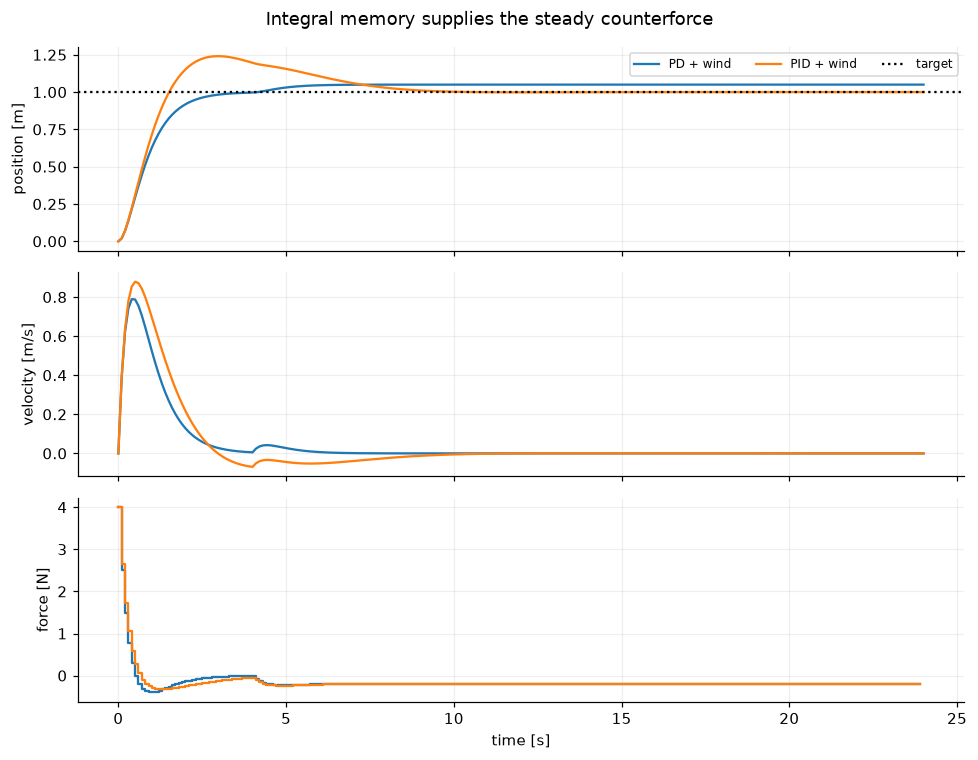

PD + wind final error: -0.0499999999999996 final force: -0.2000000000000022
PID + wind final error: -1.45280521834934e-06 final force: -0.19999961744366707


In [5]:
def pid(kp=4.0, ki=1.5, kd=3.6, limit=np.inf, antiwindup=True):
    z = 0.0
    def policy(x, k):
        nonlocal z
        error = 1.0 - x[0]
        raw = kp*error + ki*z - kd*x[1]
        applied = float(np.clip(raw, -limit, limit))
        # Freeze integration only when it pushes farther into saturation.
        if not antiwindup or (raw-applied)*error <= 0:
            z += DT*error
        return applied
    return policy

wind = lambda k: 0.2 if k >= 40 else 0.0
runs = {"PD + wind": rollout(pd_policy, steps=240, disturbance=wind),
        "PID + wind": rollout(pid(), steps=240, disturbance=wind)}
plot_runs(runs, "Integral memory supplies the steady counterforce")
for name, (xs, us) in runs.items():
    print(name, "final error:", 1-xs[-1, 0], "final force:", us[-1])
assert abs(1-runs["PID + wind"][0][-1, 0]) < 0.003


## 5. 电机有上限：积分饱和会积累错误的承诺

真实电机最多提供 $|u|\le1\,\mathrm N$。如果控制器想给 4 N，执行器只能给 1 N；误差仍在，积分器继续增长。到达目标后，积累的积分还在推车，这叫 **integrator windup**。

下面控制器增益完全相同，只改变是否使用条件积分：当已饱和且误差还想把输入往饱和方向推时暂停积分；若积分能让输入退出饱和，则允许更新。这是常见抗饱和方法之一，另有 back-calculation。

抗饱和主要修复控制器内部状态与实际执行能力脱节；它不会自动保证速度上限和位置边界。


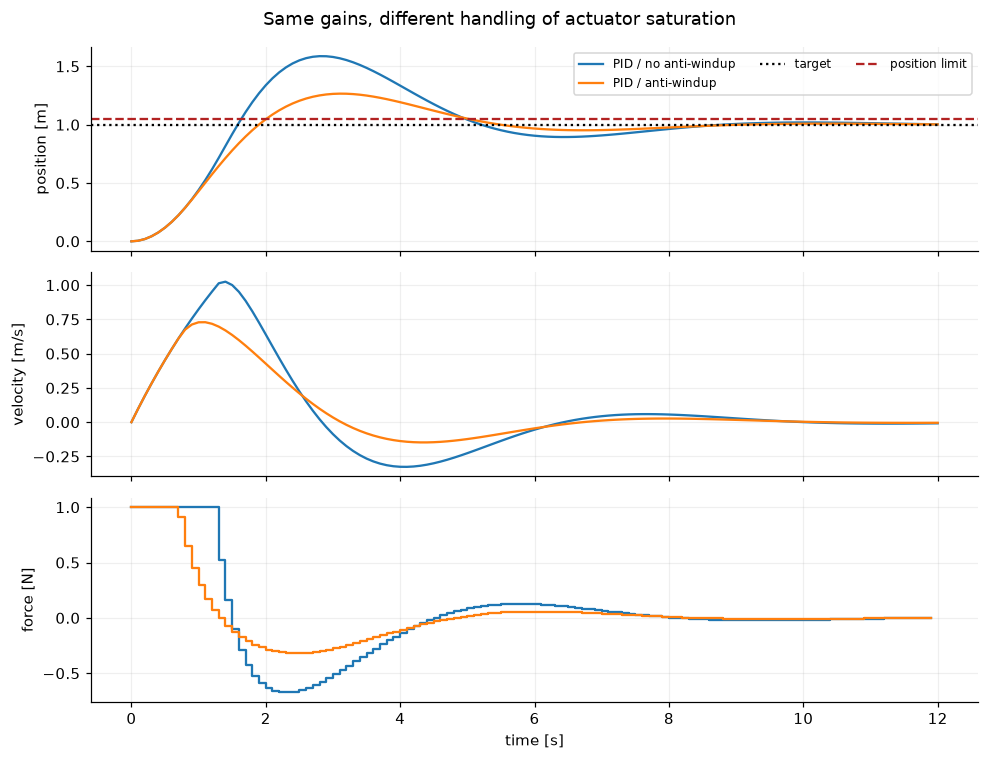

PID / no anti-windup: overshoot=0.5873 m, peak speed=1.0252 m/s
PID / anti-windup: overshoot=0.2660 m, peak speed=0.7295 m/s


In [6]:
sat_runs = {
    "PID / no anti-windup": rollout(pid(ki=3.0, limit=1, antiwindup=False)),
    "PID / anti-windup": rollout(pid(ki=3.0, limit=1, antiwindup=True)),
}
plot_runs(sat_runs, "Same gains, different handling of actuator saturation", wall=1.05)
for name, (xs, us) in sat_runs.items():
    print(f"{name}: overshoot={max(0, xs[:, 0].max()-1):.4f} m, "
          f"peak speed={np.abs(xs[:, 1]).max():.4f} m/s")
    assert np.max(np.abs(us)) <= 1


## 6. 这一代方法留下了什么问题？

PID 结构简单、无需每步求优化问题，广泛用于工业。频域工具还能直接研究带宽、噪声与稳定裕度；不是只有现代方法才关心鲁棒性。

但我们的停车任务出现了三个需求：

- **明确利用内部状态：** 速度和位置如何统一设计，而不是分别猜增益？
- **明确权衡：** 多快才值得付出多少推力？
- **提前尊重约束：** 即使此刻还没越界，是否已经刹不住了？

第二篇先解决前两个，第四篇再把约束写进未来决策。

### 自测

1. 无外力时，为什么 P 控制本例的位置阶跃可以没有稳态误差，但加外力后会有偏差？
2. 增加 $K_d$ 为什么通常能减小振荡？代价是什么？
3. 把 `ki` 改成 12，先检查连续 Routh 条件，再运行；“参数都为正”足够吗？
4. 抗饱和后的 PID 是否一定满足 $p\le1.05$？用图和数字回答。

<details><summary>参考思路</summary>

1. 对稳定闭环，本例被控对象含积分器，能跟踪常值参考；外力通道是 $GS$，其零频增益不为零。2. 速度反馈增加阻尼，也更敏感于测速噪声，过强时动作迟钝或数字闭环失稳。3. 还需要 Routh 条件及离散闭环检查；此组参数的连续阈值是 16，12 尚在连续稳定范围内，不代表离散采样性能良好。4. 不一定，控制律没有显式的未来位置约束。

</details>
